# 02 — Phân cụm người chơi theo phong cách thi đấu

Mục tiêu: tạo hồ sơ người chơi từ các chỉ số theo round, chọn số cụm, diễn giải cụm và kiểm tra độ ổn định.

Đơn vị phân tích: **một PlayerID**.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from valorant_mining.config import DATA_PROCESSED, MODEL_FEATURES
from valorant_mining.clustering import run_clustering, save_clustering
from valorant_mining.plotting import plot_clustering

players = pd.read_csv(DATA_PROCESSED / "player_features.csv")
attrition = pd.read_csv(DATA_PROCESSED / "player_attrition.csv")
display(attrition)
players[MODEL_FEATURES].describe().T


,step,players
0,Người chơi trong bảng điểm sạch,7476
1,Đủ ≥10 ván,2724
2,Đủ ≥100 round,2724
3,Đủ biến mô hình,2724


,count,mean,std,min,25%,50%,75%,max
kills_pr,2724.0,0.694460,0.091631,0.412921,0.631748,0.689528,0.752637,1.123348
deaths_pr,2724.0,0.714863,0.050060,0.552189,0.680358,0.714286,0.747386,0.923497
assists_pr,2724.0,0.251774,0.058808,0.087838,0.210084,0.246500,0.288356,0.478386
kd,2724.0,0.977505,0.152776,0.527473,0.875451,0.975409,1.075887,1.613924
acs,2724.0,200.319047,25.283978,118.884058,182.628920,199.187500,216.529500,315.149780
adr,2724.0,126.541735,19.346951,0.000000,117.040590,127.195320,138.087927,186.831288
fk_pr,2724.0,0.097322,0.040373,0.018462,0.067633,0.087184,0.119935,0.278783
fd_pr,2724.0,0.097751,0.034119,0.000000,0.073078,0.093267,0.119658,0.256098
multi_pr,2724.0,0.166007,0.037798,0.000000,0.142857,0.165947,0.189061,0.312775
acs_sd,2724.0,55.984559,10.638103,22.092985,49.374383,55.363890,62.254243,114.983667


## 1. Chạy K-Means và chọn k

Silhouette được tính cho k = 2..8. Vì mục tiêu là 3–5 nhóm có thể diễn giải, `choose_k` chỉ chọn trong khoảng 3–5; silhouette toàn miền vẫn được báo cáo để so sánh.


In [2]:
result = run_clustering(players)
result["evaluation"][["k", "inertia", "silhouette", "calinski_harabasz", "davies_bouldin"]]


,k,inertia,silhouette,calinski_harabasz,davies_bouldin
0,2,20152.649286,0.282001,1325.210213,1.319805
1,3,16927.940853,0.202191,1047.711938,1.541974
2,4,15155.680971,0.189571,885.886242,1.486031
3,5,13958.263476,0.169164,779.459381,1.552310
4,6,13181.059781,0.157927,692.145128,1.609648
5,7,12551.026705,0.150348,628.257918,1.583795
6,8,11959.087999,0.145677,584.150385,1.585721


In [3]:
print(result["summary"])
display(result["raw_profiles"].round(3))
display(result["z_profiles"][["n_players", "top_features", "low_features"]])


{'k': 3, 'best_silhouette_k': 2, 'best_silhouette': 0.282000887750527, 'silhouette': 0.20219138201907585, 'stability_mean_ari': np.float64(0.9662018880177066), 'stability_min_ari': 0.876420718201619, 'ward_ari': 0.3185820589545943, 'ward_silhouette': 0.16995224422187055, 'pca_explained_variance': 0.7051596499900913, 'n_players': 2724, 'cluster_sizes': {0: 772, 1: 871, 2: 1081}, 'cluster_labels': {0: 'Mở giao tranh · Sát thương cao', 1: 'Chết nhiều · Hiệu quả thấp', 2: 'Ít chết · Hiệu quả cao'}, 'feature_variance': {'kills_pr': 0.008, 'deaths_pr': 0.0024, 'assists_pr': 0.0034, 'kd': 0.0224, 'acs': 610.8252, 'adr': 306.585, 'fk_pr': 0.0016, 'fd_pr': 0.0011, 'multi_pr': 0.0013, 'acs_sd': 105.26, 'hs': 0.0022}}


,kills_pr,deaths_pr,assists_pr,kd,acs,adr,fk_pr,fd_pr,multi_pr,acs_sd,hs,n_players,role_duelist_share,role_initiator_share,role_controller_share,role_sentinel_share,role_other_share,win_rate,cluster_label
cluster,,,,,,,,,,,,,,,,,,,
0,0.793,0.731,0.214,1.090,228.430,143.520,0.147,0.129,0.204,64.133,0.233,772,0.694,0.105,0.086,0.116,0.0,0.487,Mở giao tranh · Sát thương cao
1,0.601,0.737,0.256,0.819,175.472,109.095,0.073,0.091,0.129,49.519,0.212,871,0.141,0.301,0.287,0.271,0.0,0.369,Chết nhiều · Hiệu quả thấp
2,0.700,0.685,0.276,1.025,200.264,128.474,0.082,0.081,0.168,55.375,0.233,1081,0.125,0.316,0.282,0.276,0.0,0.524,Ít chết · Hiệu quả cao


,n_players,top_features,low_features
cluster,,,
0,772,"First kills / round, ACS, Kills / round","Assists / round, HS %"
1,871,"Deaths / round, Assists / round, First deaths ...","K/D, Kills / round"
2,1081,"Assists / round, K/D, HS %","Deaths / round, First deaths / round"


## 2. Hình minh họa

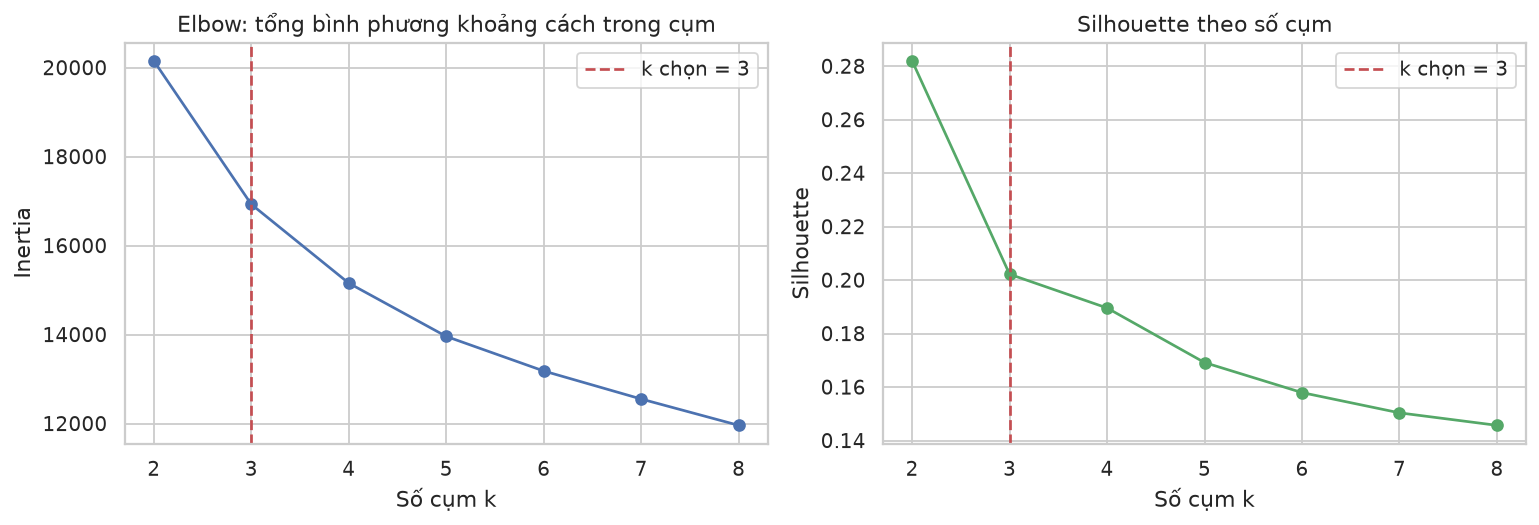

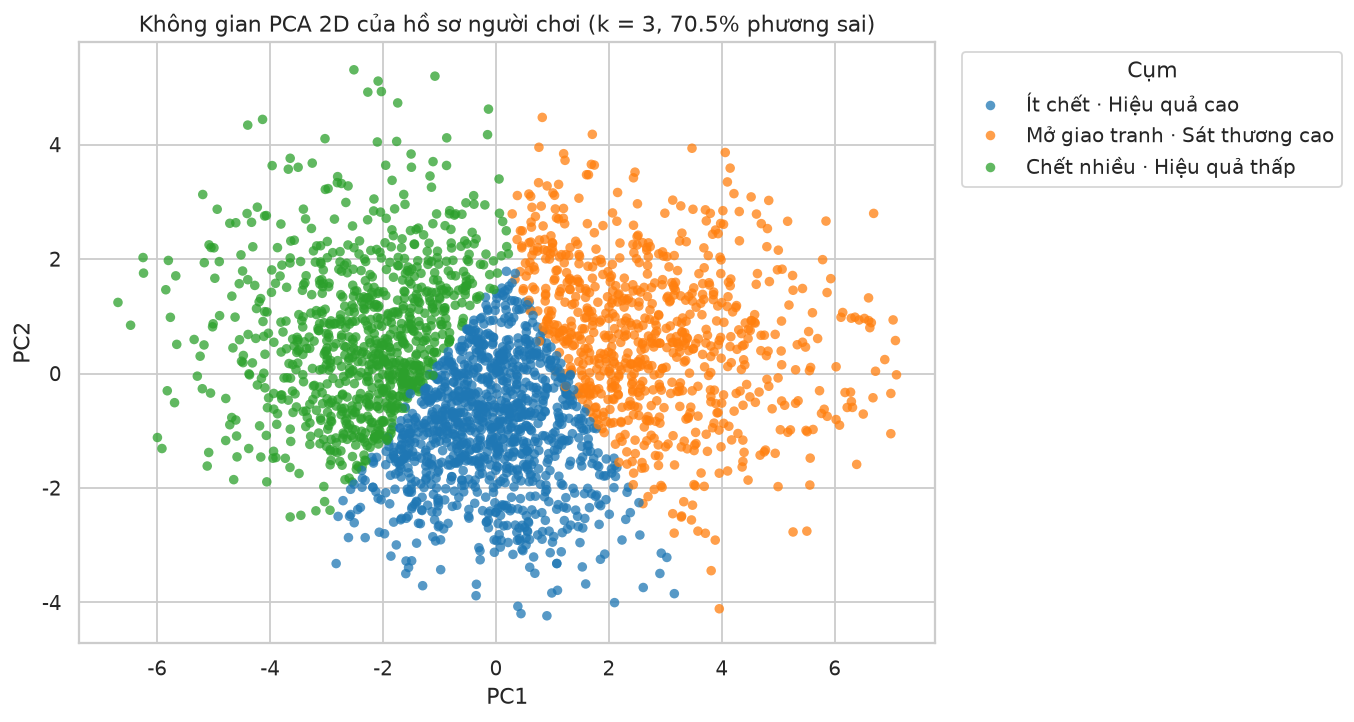

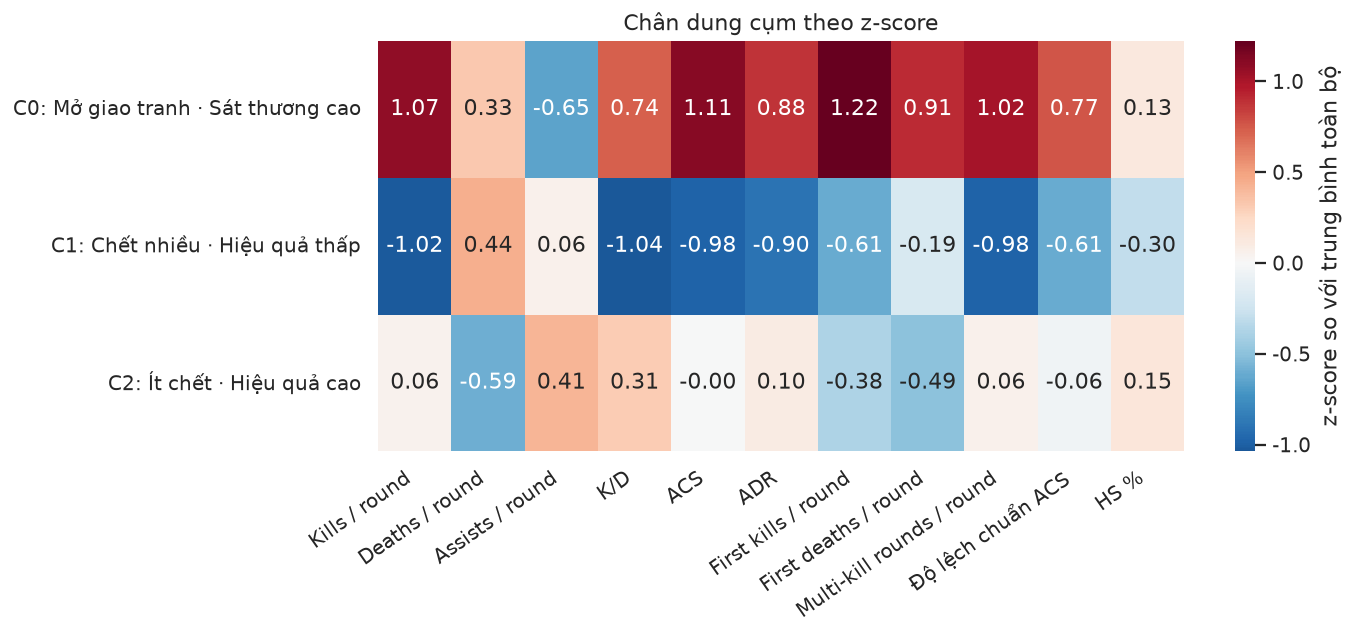

In [4]:
save_clustering(result)
plot_clustering(result)
for name in ["02_cluster_selection.png", "02_cluster_pca.png", "02_cluster_profiles.png"]:
    display(Image(filename=str(ROOT / "reports" / "figures" / name)))


## 3. Cách đọc kết quả

- **C0** có First kills/round, ACS và Kills/round cao nhất → nhóm mở giao tranh/sát thương.
- **C1** có K/D, ACS thấp và Deaths/round cao → nhóm chết nhiều, hiệu quả thấp.
- **C2** có K/D, assists và HS% cao, deaths thấp → nhóm ít chết, hiệu quả cao.

Lưu ý: C0 dùng Agent Duelist ở phần lớn số ván. Vì vậy cụm phản ánh cả **vai trò Agent** lẫn phong cách; không nên gọi cụm là “Duelist” hay “IGL” như một kết luận.
